# Lab 6 — Practical ESP32 Wi-Fi Sensing: Fall Detection with CSI

**CSCI 4900/6900 · Lecture 11 companion notebook**

This notebook has two parts.

| Part | What you do | Data |
|---|---|---|
| **A. Tsinghua *Hands-on Wireless Sensing* examples** | Run the book's MATLAB examples (Ch. 3 *CSI Features*, Ch. 4 *CSI Sanitization*, and the *Understanding CSI* speed model) **in Python**, line by line | `data/tsinghua/*.mat` (the book's test data) |
| **B. ESP32 fall detection** | Parse AtomS3R-M12 CSI in the **Lab 3 CSV format**, clean it, extract motion and speed features, build a fall detector, and evaluate it | A simulated capture (same format as Lab 3), or **your own recording** |

Everything runs on a laptop with `numpy`, `scipy`, and `matplotlib` (`scikit-learn` is optional for B10).
Run the cells from top to bottom. No board is needed until Section B11.

```bash
cd Lab-6-CSI-fall-detection
python3 -m venv .venv && source .venv/bin/activate
python3 -m pip install -r requirements.txt
jupyter lab lab6_esp32_csi_fall_detection.ipynb
```

**Sources.** Part A ports the code of the Tsinghua MobiSense group's *Hands-on Wireless Sensing with Wi-Fi* tutorial
([website](https://tns.thss.tsinghua.edu.cn/wst/docs/pre/)). Part B follows Espressif's
[ESP-CSI](https://github.com/espressif/esp-csi) workflow and the practical notes of
[ESP-CSI DIY Wi-Fi human presence detection](https://www.hackster.io/limengdu0117/esp-csi-diy-wifi-human-presence-detection-f80508).

In [1]:
from pathlib import Path
import csv, io, json, time
import numpy as np
import scipy.io as sio
from scipy import signal
from scipy.ndimage import median_filter
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (10, 3.6), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
DATA = Path("data")
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
SAVE_FIGS = True          # set False if you do not want PNGs written to ./figures
def save(name):
    if SAVE_FIGS:
        plt.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=150)
print("numpy", np.__version__)

numpy 2.5.3


---
# Part A — Tsinghua examples in Python

The book stores CSI as a 4-D tensor **`[T, S, A, L]`**:

* `T` packets (time), `S` subcarriers (frequency), `A` receive antennas, `L` HT-LTFs per packet.

The test file was recorded with an Intel-5300-style 802.11n NIC at 5.8 GHz: **999 packets × 57 subcarriers × 3 antennas × 2 LTFs**.
The transmitter is about **10 m** away, straight above the antenna plane (ground-truth direction `[0, 0, 1]`).

### A0. Parameters (same as `main.m`)

In [2]:
c  = 299_792_458.0                                    # speed of light (m/s)
bw = 20e6                                             # bandwidth (Hz)
subcarrier_freq   = np.linspace(5.8153e9, 5.8347e9, 57)
subcarrier_lambda = c / subcarrier_freq
# Antenna arrangement, first antenna is the reference. Shape [3, A]  (an L-shaped array, ~lambda/2 spacing)
antenna_loc = np.array([[0, 0, 0], [0.0514665, 0, 0], [0, 0.0514665, 0]]).T
# Linear range of the CSI phase (MATLAB 20:38, 1-based like the book)
linear_interval = np.arange(20, 39)

def load_csi(path):
    x = sio.loadmat(path)["csi"]
    return x[..., None] if x.ndim == 3 else x          # always [T, S, A, L]

TS = DATA / "tsinghua"
csi_src   = load_csi(TS / "csi_src_test.mat")         # raw CSI to analyze
csi_calib = load_csi(TS / "csi_calib_test.mat")       # CSI recorded for calibration
print("csi_src  ", csi_src.shape, csi_src.dtype)
print("csi_calib", csi_calib.shape)

csi_src   (999, 57, 3, 2) complex128
csi_calib (200, 57, 3, 1)


### A1. Look at the raw tensor

Amplitude is smooth over subcarriers (multipath fading). Raw phase wraps and drifts from packet to packet, which is why Chapter 4 exists.

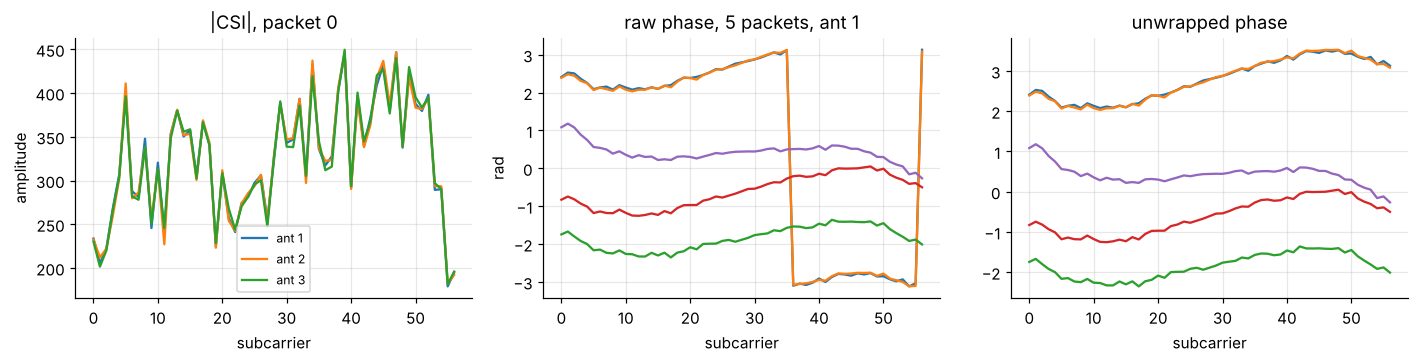

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].plot(np.abs(csi_src[0, :, :, 0])); ax[0].set(title="|CSI|, packet 0", xlabel="subcarrier", ylabel="amplitude")
ax[0].legend(["ant 1", "ant 2", "ant 3"], fontsize=8)
ax[1].plot(np.angle(csi_src[:5, :, 0, 0]).T); ax[1].set(title="raw phase, 5 packets, ant 1", xlabel="subcarrier", ylabel="rad")
ax[2].plot(np.unwrap(np.angle(csi_src[:5, :, 0, 0]), axis=1).T); ax[2].set(title="unwrapped phase", xlabel="subcarrier")
plt.tight_layout(); save("A1_raw_csi"); plt.show()

### A2. Chapter 3 — CSI features (`naive_aoa`, `naive_tof`, `naive_spectrum`)

Each function below is a line-by-line port of the MATLAB file with the same name. Shapes are written in comments as in the book.

**Angle of arrival.** For an antenna pair separated by `d` along unit vector **u**, the phase difference is
$\Delta\phi = 2\pi d\,(\mathbf u\cdot\mathbf r)/\lambda$, so $\cos\theta = \lambda\,\Delta\phi/(2\pi d)$.
Two pairs give two components of the direction vector **r**; the third follows from $\|\mathbf r\|=1$.

In [4]:
def naive_aoa(csi_data, antenna_loc, est_rco):
    # csi_data [T S A L], antenna_loc [3 A], est_rco [A]  ->  aoa_mat [3 T]
    csi_phase = np.unwrap(np.angle(csi_data), axis=1)                          # [T S A L]
    ant_diff = antenna_loc[:, 1:] - antenna_loc[:, :1]                          # [3 A-1]
    ant_diff_length = np.linalg.norm(ant_diff, axis=0)                          # [A-1]
    ant_diff_normalize = ant_diff / ant_diff_length                             # [3 A-1]
    phase_diff = (csi_phase[:, :, 1:, :] - csi_phase[:, :, :1, :]
                  - np.asarray(est_rco)[1:].reshape(1, 1, -1, 1))               # [T S A-1 L]
    phase_diff = np.unwrap(phase_diff, axis=1)
    phase_diff = np.mod(phase_diff + np.pi, 2 * np.pi) - np.pi
    cos_mat = (subcarrier_lambda.reshape(1, -1, 1, 1) * phase_diff
               / (2 * np.pi * ant_diff_length.reshape(1, 1, -1, 1)))            # [T S A-1 L]
    cos_mat_mean = cos_mat.mean(axis=(1, 3))                                    # [T A-1]
    aoa_sol = np.linalg.lstsq(ant_diff_normalize.T, cos_mat_mean.T, rcond=None)[0]   # [3 T]
    invalid = np.where(ant_diff_normalize.sum(axis=1) == 0)[0]                  # dims no pair can see
    valid = np.setdiff1d([0, 1, 2], invalid)
    rest = (1 - (aoa_sol[valid] ** 2).sum(axis=0)) / len(invalid)
    aoa_sol[invalid] = np.sqrt(np.clip(rest, 0, None))
    return aoa_sol

def naive_tof(csi_data):
    # csi_data [T S A L] -> tof_mat [T A]   (CIR = IFFT(CFR); the strongest early tap ~ direct path)
    S = csi_data.shape[1]
    ifft_point = 2 ** int(np.ceil(np.log2(S)))
    cir = np.fft.ifft(csi_data, ifft_point, axis=1).mean(axis=3)                # [T ifft_point A]
    half = cir[:, : ifft_point // 2, :]
    peak = np.argmax(np.abs(half), axis=1) + 1                                  # MATLAB 1-based index
    return peak * S / (ifft_point * bw)

def naive_spectrum(csi_data, sample_rate):
    # Conjugate multiplication removes the random per-packet phase, then STFT (MATLAB stft defaults).
    x = (csi_data * np.conj(csi_data)).real.mean(axis=(1, 2, 3))
    f, t, Z = signal.stft(x, fs=sample_rate, window="hann", nperseg=128, noverlap=96,
                          return_onesided=False, boundary=None, padded=False)
    return np.fft.fftshift(f), t, np.fft.fftshift(Z, axes=0)

Angle estimation error: 0.1620 rad  (9.28 deg)
The ground truth distance is: 10 m
The estimated distance is: 13.35 m


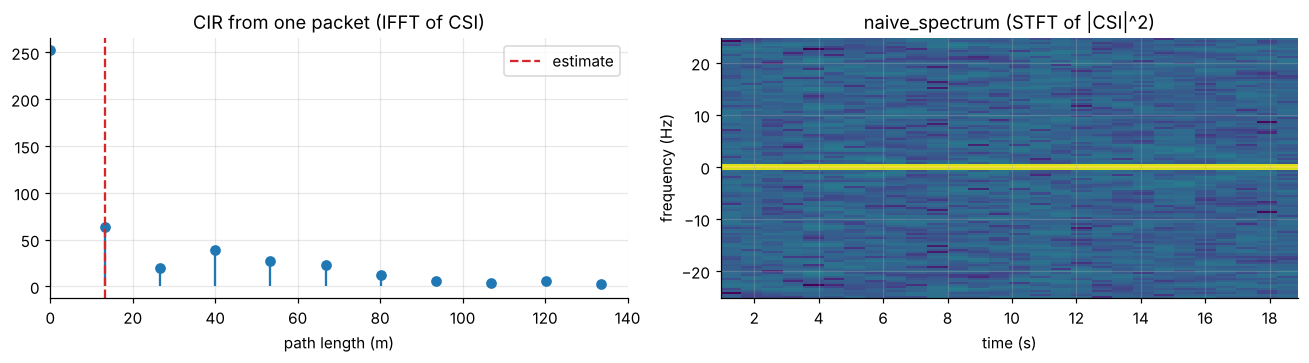

In [5]:
# Test example 1: angle estimation with imperfect CSI (no calibration yet)
aoa_mat = naive_aoa(csi_src, antenna_loc, np.zeros(3))
aoa_gt = np.array([0, 0, 1.0])
err = np.mean(np.arccos(np.clip(aoa_gt @ aoa_mat, -1, 1)))
print(f"Angle estimation error: {err:.4f} rad  ({np.degrees(err):.2f} deg)")

# Test example 2: distance estimation
tof_mat = naive_tof(csi_src)
print("The ground truth distance is: 10 m")
print(f"The estimated distance is: {np.mean(tof_mat * c):.2f} m")

# Test example 3: Doppler-like spectrum (sample_rate = 50 as in main.m)
f, t, Z = naive_spectrum(csi_src, 50)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
cir = np.abs(np.fft.ifft(csi_src[0, :, 0, 0], 64))
ax[0].stem(np.arange(64) * 57 / (64 * bw) * c, cir, basefmt=" ")
ax[0].axvline(np.mean(tof_mat * c), color="C3", ls="--", label="estimate")
ax[0].set(title="CIR from one packet (IFFT of CSI)", xlabel="path length (m)", xlim=(0, 140)); ax[0].legend()
ax[1].pcolormesh(t, f, 20 * np.log10(np.abs(Z) + 1e-9), shading="auto")
ax[1].set(title="naive_spectrum (STFT of |CSI|^2)", xlabel="time (s)", ylabel="frequency (Hz)")
plt.tight_layout(); save("A2_features"); plt.show()

The distance is only *roughly* right: 20 MHz gives a delay bin of 1/20 MHz = 50 ns ≈ **15 m** of path, and the NIC adds unknown timing offsets.
This is why the book calls these functions *naive*.

### A3. Chapter 4 — CSI sanitization

Commodity Wi-Fi hardware adds errors that are **not** caused by the environment:

| Error | Effect on CSI | Book's fix | Function |
|---|---|---|---|
| Nonlinear amplitude/phase response of the RF chain | fixed curve over subcarriers | divide by a calibration template | `set_template`, `nonlinear_calib` |
| STO / SFO / packet boundary delay | phase slope over subcarriers that changes **every packet** | ratio or conjugate product **between antennas** (same clock) | `sto_calib_div`, `sto_calib_mul` |
| CFO | common phase rotation over time | compare the two HT-LTFs (4 µs apart) | `cfo_calib` |
| Radio chain offset (RCO) | constant phase offset per antenna | measure at a known angle | `rco_calib` |
| AGC | amplitude jumps | divide by the reported gain | `agc_calib` |

In [6]:
def set_template(csi_calib, linear_interval):
    T, S, A, E = csi_calib.shape
    csi_amp = np.abs(csi_calib)
    csi_phase = np.unwrap(np.angle(csi_calib), axis=1)
    amp_template = (csi_amp / csi_amp.mean(axis=1, keepdims=True)).mean(axis=0, keepdims=True)   # [1 S A L]
    x, idx = np.arange(1, S + 1), linear_interval - 1
    nonlinear_err = np.zeros_like(csi_phase)
    for p in range(T):
        for a in range(A):
            for e in range(E):
                k, b = np.polyfit(linear_interval, csi_phase[p, idx, a, e], 1)   # 'poly1' fit
                nonlinear_err[p, :, a, e] = csi_phase[p, :, a, e] - (k * x + b)
    phase_template = nonlinear_err.mean(axis=0, keepdims=True)
    phase_template[:, idx] = 0
    return amp_template * np.exp(1j * phase_template)                          # [1 S A L]

def nonlinear_calib(csi, template):
    csi_unwrap = np.abs(csi) * np.exp(1j * np.unwrap(np.angle(csi), axis=1))
    return csi_unwrap / template

def sto_calib_mul(csi):          # antenna a times conj(antenna a+1)
    return csi * np.conj(np.roll(csi, -1, axis=2))

def sto_calib_div(csi):          # antenna a divided by antenna a+1
    return csi / np.roll(csi, -1, axis=2)

def cfo_calib(csi):              # needs two HT-LTFs; returns rad/s per packet
    phase_diff = (np.angle(csi[..., 1]) - np.angle(csi[..., 0])).mean(axis=2)
    return (phase_diff / 4e-6).mean(axis=1)

def rco_calib(csi_calib):
    csi_phase = np.unwrap(np.angle(csi_calib), axis=0)
    avg = np.array([csi_phase[:, :, a, 0].mean() for a in range(csi_calib.shape[2])])
    return avg - avg[0]

def agc_calib(csi, agc):         # agc: per-packet gain reported by the NIC, shape [T]
    return csi / np.asarray(agc).reshape(-1, 1, 1, 1)

def naive_intrusion(csi, threshold):
    xn = csi / np.abs(csi).mean()
    spec = np.abs(np.fft.fft(xn, axis=0))[1:50].mean(axis=0).ravel()           # low-frequency energy
    med = np.median(spec); mad = 1.4826 * np.median(np.abs(spec - med))        # rmoutliers (median)
    indicator = spec[np.abs(spec - med) <= 3 * mad].mean()
    return indicator > threshold, indicator

In [7]:
template = set_template(csi_calib, linear_interval)
ref = load_csi(TS / "calib_template_test.mat")
print("max |python template - book template| =", np.abs(template - ref).max())

csi_remove_nonlinear = nonlinear_calib(csi_src, template)
csi_remove_sto = sto_calib_div(csi_src)
est_cfo = cfo_calib(csi_src)
est_rco = rco_calib(csi_calib)
print("estimated CFO (Hz), first packets:", np.round(est_cfo[:3] / (2 * np.pi), 2))
print("estimated RCO (rad):", np.round(est_rco, 3))

# Test example 1: angle with and without RCO removal
for name, rco in [("without", np.zeros(3)), ("with", est_rco)]:
    e = np.mean(np.arccos(np.clip(aoa_gt @ naive_aoa(csi_src, antenna_loc, rco), -1, 1)))
    print(f"Angle estimation error {name:7s} RCO removal: {np.degrees(e):6.2f} deg")

# Test example 2: intrusion detection with and without SFO/PDD removal
print("Intrusion detection without SFO/PDD removal:", naive_intrusion(csi_src, 3))
print("Intrusion detection with    SFO/PDD removal:", naive_intrusion(csi_remove_sto, 3))

max |python template - book template| = 5.978733960281817e-16
estimated CFO (Hz), first packets: [0. 0. 0.]
estimated RCO (rad): [0.    0.898 0.379]
Angle estimation error without RCO removal:   9.28 deg
Angle estimation error with    RCO removal:   1.05 deg
Intrusion detection without SFO/PDD removal: (np.True_, np.float64(33.31651353345626))
Intrusion detection with    SFO/PDD removal: (np.False_, np.float64(0.5902544153387033))


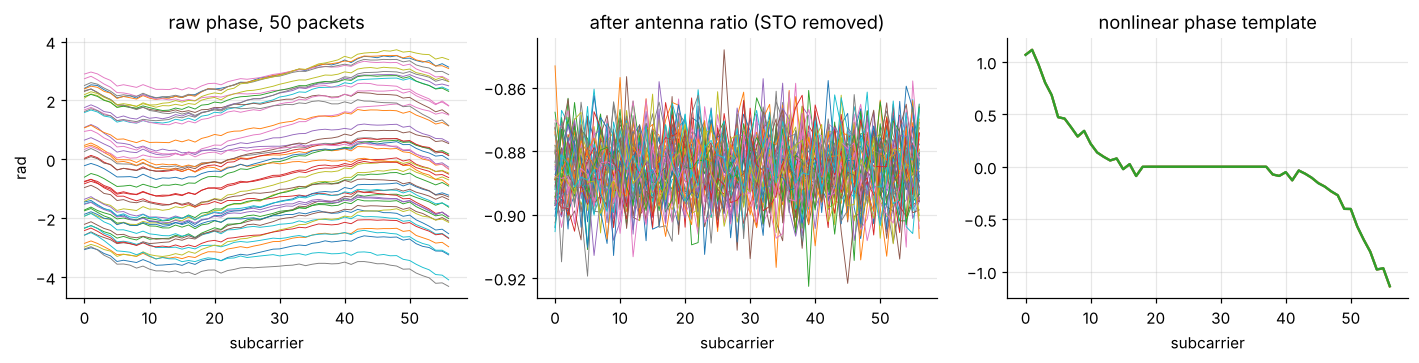

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].plot(np.unwrap(np.angle(csi_src[:50, :, 0, 0]), axis=1).T, lw=0.6)
ax[0].set(title="raw phase, 50 packets", xlabel="subcarrier", ylabel="rad")
ax[1].plot(np.angle(csi_remove_sto[:50, :, 0, 0]).T, lw=0.6)
ax[1].set(title="after antenna ratio (STO removed)", xlabel="subcarrier")
ax[2].plot(np.angle(template[0, :, :, 0])); ax[2].set(title="nonlinear phase template", xlabel="subcarrier")
plt.tight_layout(); save("A3_sanitization"); plt.show()

The antenna-ratio trick needs **two antennas on the same clock**. The AtomS3R-M12 (ESP32-S3) has **one antenna**, so in Part B we cannot use it.
We will work with **amplitude/power** instead, which does not depend on the random phase.

### A4. *Understanding CSI* — speed from the autocorrelation (the scattering model)

In a room with rich scattering, CSI is a sum of static scatterers (walls, furniture) and dynamic scatterers (the moving body).
If the dynamic scatterers move at speed $v$ and their directions are spread uniformly, the tutorial shows

$$\rho_H(\tau) \approx \mathrm{sinc}(k v \tau)=\frac{\sin(kv\tau)}{kv\tau},\qquad k=\frac{2\pi}{\lambda}.$$

Find a landmark of the measured ACF at lag $\tau_0$, match it to the same landmark of $\mathrm{sinc}(x)$ at $x_0$, and

$$v = \frac{x_0}{k\,\tau_0} = \frac{x_0\,\lambda}{2\pi\,\tau_0}.$$

`sinc(x)` has its **first valley at x₀ = 4.49** (value −0.22) and its first peak after the main lobe at x = 7.73.
Below we simulate the model and check that the ACF really follows `sinc`.

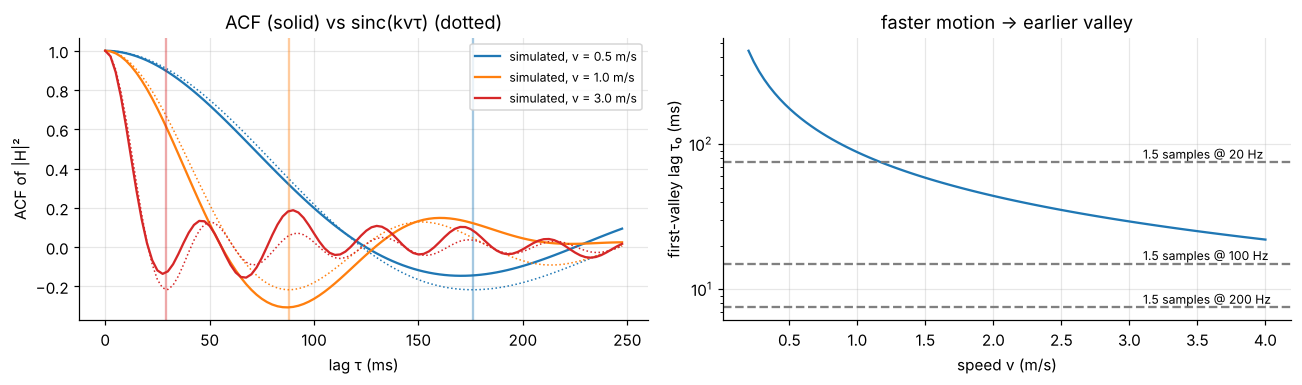

lambda at 2.437 GHz = 12.3 cm;  v = 3 m/s -> tau0 = 29.3 ms


In [9]:
X_VALLEY, X_PEAK = 4.4934, 7.7253
lam24 = c / 2.437e9                     # ESP32 on Wi-Fi channel 6
k24 = 2 * np.pi / lam24
fs_sim = 400
tt = np.arange(0, 30, 1 / fs_sim)
rng = np.random.default_rng(0)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for v, col in zip([0.5, 1.0, 3.0], ["C0", "C1", "C3"]):
    u = rng.uniform(-1, 1, 200)                                   # cos(angle), uniform on a sphere
    b = rng.rayleigh(1, 200) * np.exp(1j * rng.uniform(0, 2 * np.pi, 200))
    H = 3 + (b[None, :] * np.exp(1j * k24 * v * tt[:, None] * u[None, :])).sum(1) / np.sqrt(200)
    P = np.abs(H) ** 2; P -= P.mean()
    lags = np.arange(int(0.25 * fs_sim))
    acf = np.array([np.mean(P[: len(P) - L] * P[L:]) for L in lags]) / np.mean(P * P)
    tau = lags / fs_sim
    ax[0].plot(tau * 1e3, acf, color=col, label=f"simulated, v = {v} m/s")
    ax[0].plot(tau * 1e3, np.sinc(k24 * v * tau / np.pi), color=col, ls=":", lw=1)
    tau0 = X_VALLEY / (k24 * v)
    ax[0].axvline(tau0 * 1e3, color=col, alpha=0.4)
ax[0].set(xlabel="lag τ (ms)", ylabel="ACF of |H|²", title="ACF (solid) vs sinc(kvτ) (dotted)"); ax[0].legend(fontsize=8)
v_axis = np.linspace(0.2, 4, 100)
ax[1].plot(v_axis, X_VALLEY / (k24 * v_axis) * 1e3)
for fs_ in [20, 100, 200]:
    ax[1].axhline(1.5e3 / fs_, ls="--", color="gray"); ax[1].text(3.1, 1.5e3 / fs_ * 1.06, f"1.5 samples @ {fs_} Hz", fontsize=8)
ax[1].set(xlabel="speed v (m/s)", ylabel="first-valley lag τ₀ (ms)", yscale="log", title="faster motion → earlier valley")
plt.tight_layout(); save("A4_acf_sinc"); plt.show()
print(f"lambda at 2.437 GHz = {lam24*100:.1f} cm;  v = 3 m/s -> tau0 = {X_VALLEY/(k24*3)*1e3:.1f} ms")

**Take-away for hardware.** A 3 m/s fall puts the valley at about **29 ms**. At the Lab 3 default of **20 packets/s** (one sample every 50 ms) the valley is invisible,
so walking and falling look the same. We need roughly **100–200 packets/s**.

---
# Part B — ESP32 (AtomS3R-M12) fall detection

### B0. What the board sends (Lab 3 format)

Lab 3's firmware prints one CSV line per CSI callback:

```text
type,seq,timestamp_us,mac,rssi,noise_floor,channel,sig_mode,mcs,cwb,len,first_word_invalid,data
CSI_DATA,0,4294000123,a4:cf:12:00:5e:01,-61,-96,6,1,7,0,128,0,"[3,-21,0,0,...]"
```

* `data` holds **128 signed bytes = 64 LLTF subcarriers**, each stored as **(imaginary, real)**.
* Pair index → subcarrier: `0…31` then `−32…−1`. Only **−26…−1, 1…26** carry energy (52 subcarriers). DC and guards are zero.
* `timestamp_us` is a 32-bit microsecond counter that **wraps**; packets arrive **unevenly** and some are **dropped**.

In [10]:
C = 299_792_458.0
FC = 2.437e9                                   # channel 6; change if your AP uses another channel
LAM = C / FC
DF = 312.5e3                                   # subcarrier spacing (Hz)
SC_ORDER = np.r_[np.arange(0, 32), np.arange(-32, 0)]          # pair index -> subcarrier number
VALID_SC = np.r_[np.arange(-26, 0), np.arange(1, 27)]           # 52 used subcarriers
HEADER = "type,seq,timestamp_us,mac,rssi,noise_floor,channel,sig_mode,mcs,cwb,len,first_word_invalid,data"

def load_lab3_csv(source):
    # source: path to a CSV recorded by Lab 3 (plot_csi.py --save-csv) or the CSV text itself.
    is_text = isinstance(source, str) and ("\n" in source or source.startswith("CSI_DATA"))
    text = source if is_text else Path(source).read_text()
    rows = [r for r in csv.reader(io.StringIO(text)) if r and r[0] == "CSI_DATA"]
    ts = np.array([int(r[2]) for r in rows], dtype=np.int64)
    rssi = np.array([int(r[4]) for r in rows])
    invalid = np.array([int(r[11]) for r in rows], dtype=bool)
    raw = [json.loads(r[12]) for r in rows]
    raw = np.array([x[:128] + [0] * (128 - len(x)) for x in raw], dtype=float)   # LLTF only
    Hc = raw[:, 1::2] + 1j * raw[:, 0::2]          # (imag, real) pairs -> complex
    Hc[invalid, :2] = np.nan                       # first four bytes are not valid
    d = np.diff(ts); d[d < 0] += 2 ** 32           # unwrap the 32-bit counter
    t = np.r_[0, np.cumsum(d)] / 1e6
    col = {sc: i for i, sc in enumerate(SC_ORDER)}
    H = Hc[:, [col[s] for s in VALID_SC]]           # [T, 52] ordered -26..26
    return t, H, rssi

line = 'CSI_DATA,0,4294000123,a4:cf:12:00:5e:01,-61,-96,6,1,7,0,128,0,"[' + ",".join(["0", "0"] + ["-5", "20"] * 63) + ']"'
t1, H1, r1 = load_lab3_csv(HEADER + "\n" + line)
print("one packet ->", H1.shape, "| subcarrier -26 value:", H1[0, 0], "| rssi", r1[0])

one packet -> (1, 52) | subcarrier -26 value: (20-5j) | rssi -61


### B1. A simulated capture (a "digital twin" of Lab 3)

So that everyone can run the full pipeline today, the next cell **simulates** an AtomS3R capture with the scattering model from A4 and writes it in exactly the Lab 3 format.
It includes the real-world problems you will meet with the board: **random phase per packet (CFO/STO), AGC gain jumps, int8 quantization, noise, jittered packet times, and dropped packets.**

You do not need to read this cell in detail. In B11 you replace the simulated file with your own recording.

Activity speeds are in m/s of the moving body parts. A fall accelerates to 2.5–3.8 m/s in about 0.5 s and stops at impact.

In [11]:
def speed_profile(kind, t, rng):
    # -> (speed of the moving scatterers in m/s, amplitude of the body's scattering)
    T = t[-1] if len(t) else 0
    if kind == "empty": return np.zeros_like(t), 0.0
    if kind == "stand": return 0.04 + 0.02 * rng.standard_normal(len(t)).clip(-1, 1), 1.0
    if kind == "still": return np.zeros_like(t), 1.0          # sitting/lying still: breathing only
    if kind == "walk":
        v0 = rng.uniform(0.8, 1.3); return v0 * (1 + 0.3 * np.sin(2 * np.pi * rng.uniform(1.6, 2.0) * t)), 1.0
    if kind in ("sit", "standup", "liedown"):
        vp = rng.uniform(0.6, 1.1) if kind == "liedown" else rng.uniform(0.5, 1.0)
        return vp * np.sin(np.pi * t / T) ** 2, 1.0
    if kind == "fall":
        tf, vp = rng.uniform(0.45, 0.7), rng.uniform(2.5, 3.8)    # fall time (s), impact speed (m/s)
        return np.where(t < tf, vp * (t / tf) ** 1.5, vp * np.exp(-(t - tf) / 0.05)), 1.0
    if kind == "drop":                                            # a dropped object: fast but small
        return np.where(t < 0.4, 3.9 * t / 0.4, 0.0), 0.25
    raise ValueError(kind)

DUR = {"sit": (1.2, 2.0), "standup": (1.0, 1.6), "liedown": (1.8, 2.8)}

def simulate_session(script, fs=100.0, seed=0, room_seed=None, n_scat=60, snr_db=28, drop_rate=0.03):
    # script: [(activity, seconds), ...] -> (Lab 3 CSV text, labels [(t0, t1, activity)], ground truth)
    rng = np.random.default_rng(seed)
    rrng = np.random.default_rng(seed if room_seed is None else room_seed)
    total = sum(d for _, d in script)
    t = np.cumsum(rng.gamma(20.0, 1 / (20.0 * fs), int(total * fs * 1.05))); t = t[t < total]
    keep = rng.random(len(t)) > drop_rate
    v = np.zeros(len(t)); amp = np.zeros(len(t)); labels = []; t0 = 0.0
    for kind, d in script:
        m = (t >= t0) & (t < t0 + d)
        v[m], amp[m] = speed_profile(kind, t[m] - t0, rng)
        labels.append((t0, t0 + d, kind)); t0 += d
    breathing = np.where(amp > 0, 0.004 * np.sin(2 * np.pi * rng.uniform(0.2, 0.33) * t), 0.0)
    f_sc = SC_ORDER * DF
    tau_s = np.sort(rrng.uniform(10e-9, 120e-9, 6)); tau_s[0] = rrng.uniform(8e-9, 15e-9)
    a_s = rrng.rayleigh(1.0, 6) * np.exp(-np.arange(6) * 0.35) * np.exp(1j * rrng.uniform(0, 2 * np.pi, 6))
    H_static = (a_s * np.exp(-2j * np.pi * f_sc[:, None] * tau_s)).sum(1)              # the room
    u = rng.uniform(-1, 1, n_scat); tau_d = rng.uniform(20e-9, 60e-9, n_scat)            # the body
    b = rng.rayleigh(1.0, n_scat) * np.exp(1j * rng.uniform(0, 2 * np.pi, n_scat))
    b *= 0.45 * np.linalg.norm(a_s) / np.linalg.norm(b)
    k = 2 * np.pi / LAM
    disp = np.cumsum(v * np.diff(t, prepend=0.0))
    ph = k * np.outer(disp, u) + 3 * k * np.outer(breathing, u)
    D = (amp[:, None, None] * b * np.exp(1j * ph)[:, None, :] * np.exp(-2j * np.pi * f_sc[None, :, None] * tau_d)).sum(2)
    H = H_static[None, :] + D
    g = np.ones(len(t))                                                                    # AGC jumps
    for ts in rng.uniform(0, total, rng.integers(2, 6)):
        g[t >= ts] *= 10 ** (rng.choice([-1, 1]) * rng.uniform(0.8, 2.0) / 20)
    sto = rng.normal(0, 30e-9, len(t))                                                     # timing offset
    Hm = g[:, None] * H * np.exp(1j * (rng.uniform(-np.pi, np.pi, len(t))[:, None] - 2 * np.pi * f_sc * sto[:, None]))
    Hm += np.sqrt(np.mean(np.abs(Hm) ** 2) / 10 ** (snr_db / 10) / 2) * (rng.standard_normal(Hm.shape) + 1j * rng.standard_normal(Hm.shape))
    used = np.isin(SC_ORDER, VALID_SC); Hm[:, ~used] = 0
    Q = Hm * 22 / np.median(np.abs(Hm[:, used]))
    re = np.clip(np.rint(Q.real), -128, 127).astype(int); im = np.clip(np.rint(Q.imag), -128, 127).astype(int)
    rssi = np.rint(-62 + 20 * np.log10(np.abs(Hm[:, used]).mean(1) / np.abs(Hm[:, used]).mean())).astype(int)
    out = io.StringIO(); w = csv.writer(out, lineterminator="\n"); out.write(HEADER + "\n")
    ts_us = (np.rint(t * 1e6).astype(np.int64) + 4_294_000_000) % 2 ** 32      # wraps like the board's counter
    for seq, i in enumerate(np.where(keep)[0]):
        raw = np.empty(128, int); raw[0::2] = im[i]; raw[1::2] = re[i]
        w.writerow(["CSI_DATA", seq, int(ts_us[i]), "a4:cf:12:00:5e:01", int(rssi[i]), -96, 6, 1, 7, 0, 128, 0,
                    json.dumps(raw.tolist(), separators=(",", ":"))])
    return out.getvalue(), labels, dict(t=t, v=v)

In [12]:
FS = 100        # packets per second requested (Lab 3: PING_INTERVAL_MS = 10)
demo_script = [("empty", 15), ("walk", 10), ("stand", 4), ("sit", 1.6), ("still", 8), ("standup", 1.3),
               ("walk", 8), ("fall", 1.0), ("still", 20)]
csv_text, labels, truth = simulate_session(demo_script, fs=FS, seed=1)

SIM = DATA / "esp32_sim"; SIM.mkdir(parents=True, exist_ok=True)
(SIM / "demo_session.csv").write_text(csv_text)
with open(SIM / "demo_session_labels.csv", "w", newline="") as fh:
    csv.writer(fh).writerows([("start_s", "end_s", "activity")] + [(round(a, 3), round(b, 3), k) for a, b, k in labels])
print(csv_text.splitlines()[1][:150], "...")
print(len(csv_text.splitlines()) - 1, "packets written to", SIM / "demo_session.csv")

CSI_DATA,0,4294010620,a4:cf:12:00:5e:01,-61,-96,6,1,7,0,128,0,"[0,0,6,9,2,11,-4,13,-9,13,-14,11,-19,7,-21,1,-23,-4,-23,-10,-23,-18,-17,-24,-13,-29,-6, ...
6715 packets written to data/esp32_sim/demo_session.csv


### B2. Load the capture and look at the problems

`CSV_PATH` is the only line you change when you switch to your own recording.

6715 packets over 68.9 s -> 97.5 packets/s;  gaps > 30 ms: 3


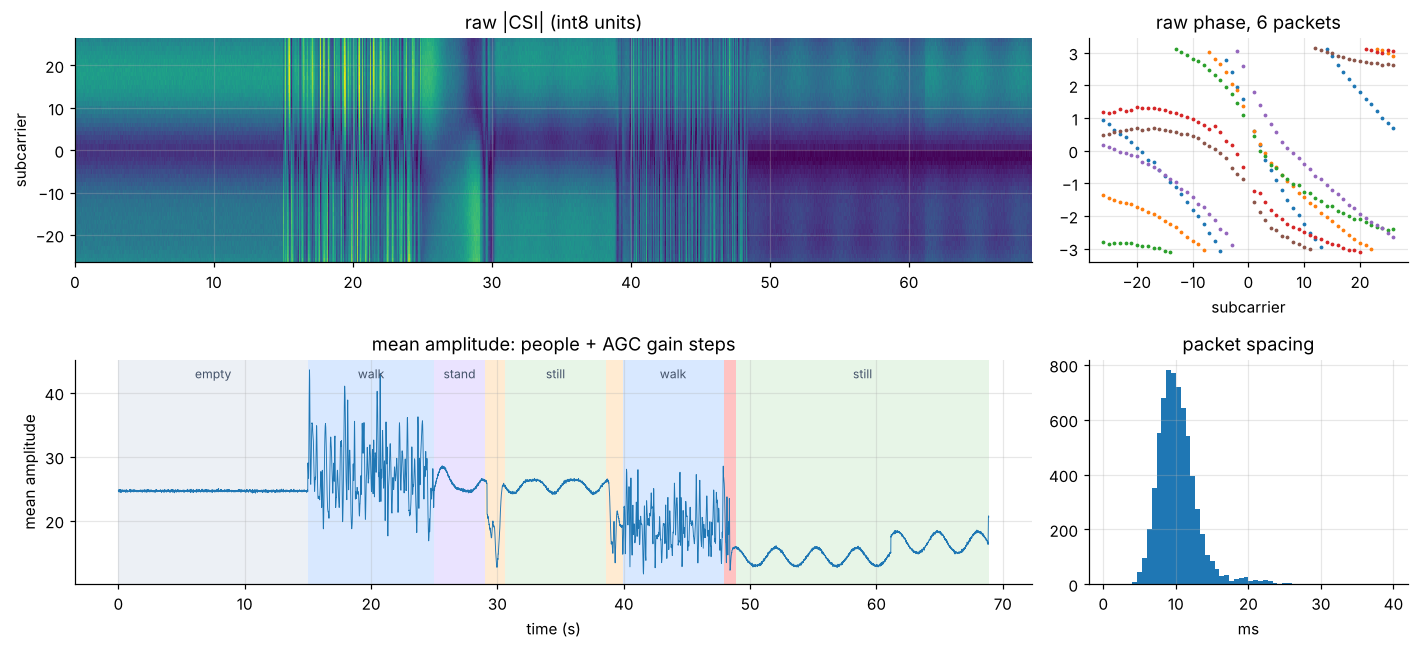

In [13]:
CSV_PATH = SIM / "demo_session.csv"            # <- your file, e.g. "captures/fall01.csv"
LABELS_PATH = SIM / "demo_session_labels.csv"  # optional; None if you have no labels

t, H, rssi = load_lab3_csv(CSV_PATH)
labels = [(float(a), float(b), k) for a, b, k in list(csv.reader(open(LABELS_PATH)))[1:]] if LABELS_PATH else []
dt = np.diff(t)
print(f"{len(t)} packets over {t[-1]:.1f} s -> {len(t)/t[-1]:.1f} packets/s;  gaps > 30 ms: {(dt > 0.03).sum()}")

ACT_COLORS = {"empty": "#e8edf3", "walk": "#cfe3ff", "stand": "#e5dcff", "sit": "#ffe6c7", "standup": "#ffe6c7",
              "still": "#e2f3e2", "liedown": "#ffe6c7", "fall": "#ffb3b3", "drop": "#f7d3f0"}
def shade(ax, labels, text=True):
    for a, b, k in labels:
        ax.axvspan(a, b, color=ACT_COLORS.get(k, "#eee"), alpha=0.8, lw=0)
        if text and b - a > 2.5: ax.text((a + b) / 2, 0.97, k, transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=8, color="#44536a")

fig, ax = plt.subplots(2, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [3, 1]})
A = np.abs(H)
ax[0, 0].pcolormesh(t, VALID_SC, A.T, shading="auto", cmap="viridis")
ax[0, 0].set(title="raw |CSI| (int8 units)", ylabel="subcarrier")
ax[1, 0].plot(t, A.mean(1), lw=0.6, label="mean |CSI|"); shade(ax[1, 0], labels)
ax[1, 0].set(xlabel="time (s)", ylabel="mean amplitude", title="mean amplitude: people + AGC gain steps")
ax[0, 1].plot(VALID_SC, np.angle(H[:6]).T, ".", ms=3); ax[0, 1].set(title="raw phase, 6 packets", xlabel="subcarrier")
ax[1, 1].hist(dt * 1e3, bins=60, range=(0, 40)); ax[1, 1].set(title="packet spacing", xlabel="ms")
plt.tight_layout(); save("B2_raw_problems"); plt.show()

**What you should see.** (1) The phase is random from packet to packet: with one antenna we cannot fix it, so we drop phase.
(2) The mean amplitude has **steps** (AGC). (3) Packets are not evenly spaced.

### B3. Clean the amplitude

1. **AGC:** divide each packet by its own mean amplitude across subcarriers (common gain cancels; the frequency *shape* that people change remains).
2. **Hampel filter:** replace isolated spikes by the local median.
3. **Resample** onto a uniform 100 Hz grid, because ACF and STFT assume uniform sampling.

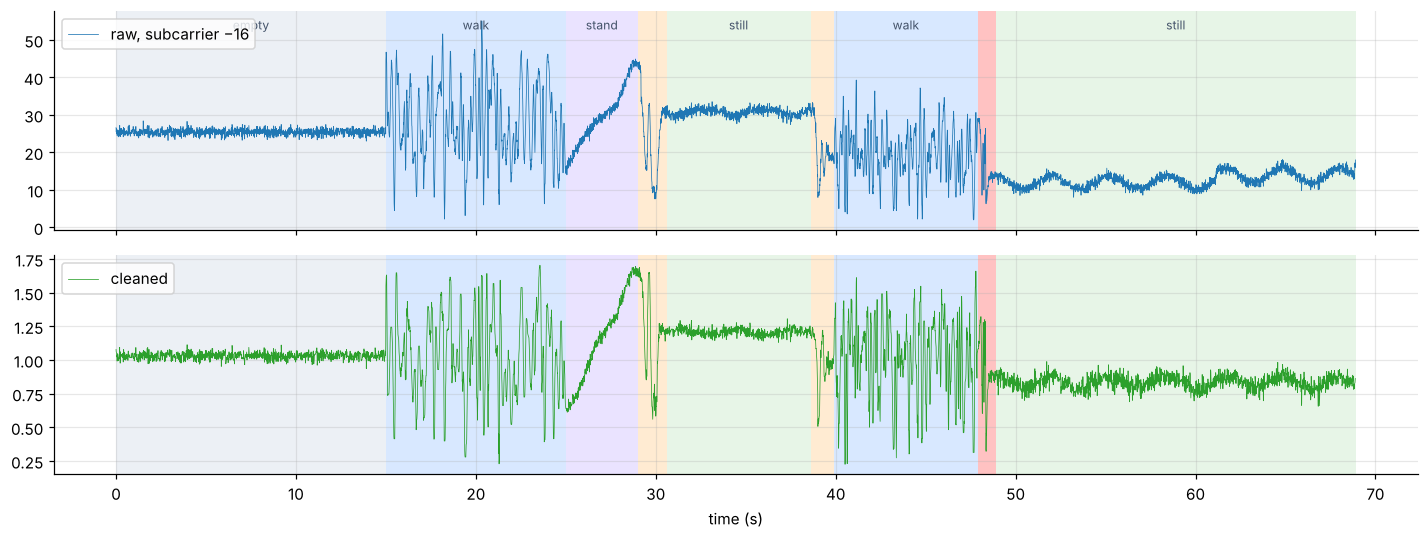

In [14]:
def hampel(x, k=5, nsig=3.0):
    med = median_filter(x, size=(2 * k + 1, 1), mode="nearest")
    mad = 1.4826 * median_filter(np.abs(x - med), size=(2 * k + 1, 1), mode="nearest")
    y = x.copy(); bad = np.abs(x - med) > nsig * mad + 1e-9; y[bad] = med[bad]
    return y

def preprocess(t, H, fs=100.0):
    A = np.abs(H)
    A = A / np.nanmean(A, axis=1, keepdims=True)                 # 1. AGC normalization
    A = np.nan_to_num(hampel(A), nan=1.0)                        # 2. outliers
    tu = np.arange(0, t[-1], 1 / fs)                             # 3. uniform grid
    Au = np.stack([np.interp(tu, t, A[:, j]) for j in range(A.shape[1])], axis=1)
    return tu, Au

tu, Au = preprocess(t, H, FS)
fig, ax = plt.subplots(2, 1, figsize=(13, 5), sharex=True)
ax[0].plot(t, np.abs(H)[:, 10], lw=0.5, label="raw, subcarrier −16"); ax[0].legend(loc="upper left")
ax[1].plot(tu, Au[:, 10], lw=0.5, color="C2", label="cleaned"); ax[1].legend(loc="upper left")
for a in ax: shade(a, labels, text=(a is ax[0]))
ax[1].set_xlabel("time (s)"); plt.tight_layout(); save("B3_clean"); plt.show()

### B4. Feature 1 — motion energy and presence ("jitter" and "wander")

* **Motion energy** = how much the cleaned amplitude fluctuates in a 1 s window (averaged over subcarriers). It is high while someone moves and low otherwise.
  ESP-CSI's `esp-radar` calls this kind of feature *jitter*.
* **Wander** = how far the 1 s average subcarrier profile has moved away from the **empty-room profile**. A person who is lying still does not move, but their body still changes the static multipath, so wander stays high.

Thresholds come from a **calibration** recording of the empty room — the same idea as the hackster project's "calibrate the empty room, then `variance > threshold`".

{'me_still': np.float64(0.048), 'me_move': np.float64(0.096), 'wander_present': 0.03, 'v_fall': 1.7, 'quiet_start': 1.5, 'quiet_len': 5.0}


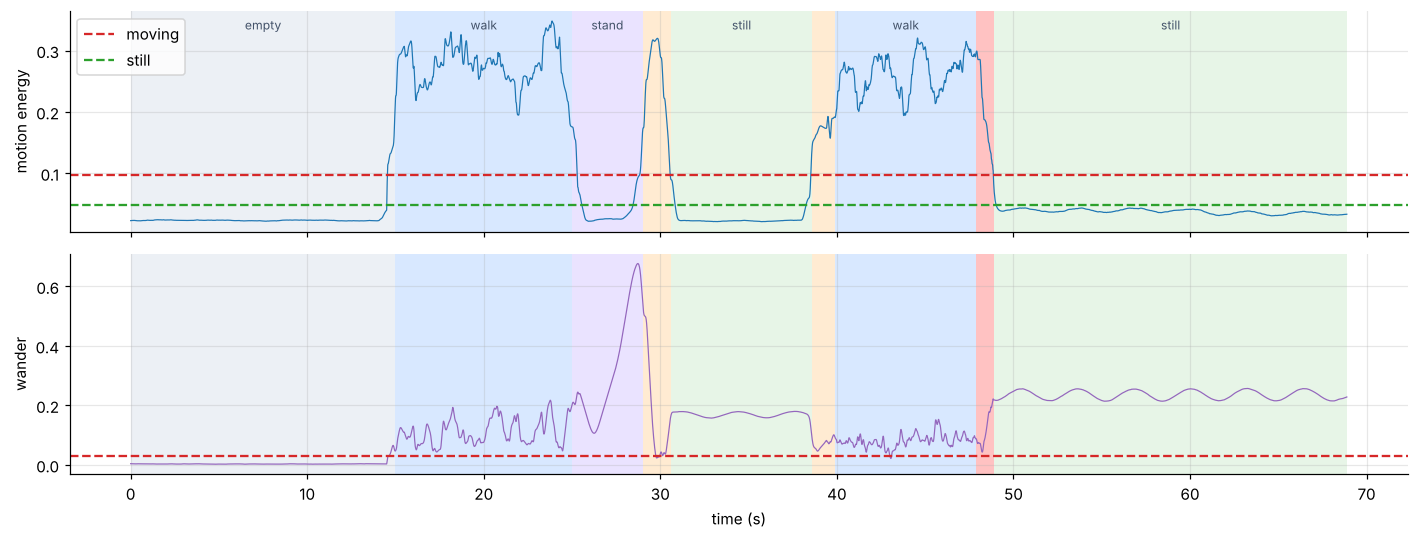

In [15]:
def moving(x, w):
    k = np.ones(w)
    return np.convolve(x, k, mode="same") / np.convolve(np.ones_like(x), k, mode="same")

def motion_energy(Au, fs, win=1.0):
    w = int(win * fs)
    detr = Au - np.stack([moving(Au[:, j], w) for j in range(Au.shape[1])], 1)
    return np.sqrt(np.stack([moving(detr[:, j] ** 2, w) for j in range(Au.shape[1])], 1).mean(1))

def wander(Au, fs, baseline_profile, win=1.0):
    w = int(win * fs)
    prof = np.stack([moving(Au[:, j], w) for j in range(Au.shape[1])], 1)
    return np.sqrt(((prof - baseline_profile) ** 2).mean(1))

CALIB = (1.0, 12.0)                                      # seconds of the empty-room recording
cal = (tu > CALIB[0]) & (tu < CALIB[1])
me = motion_energy(Au, FS)
baseline = Au[cal].mean(0)
wd = wander(Au, FS, baseline)
me_empty = np.percentile(me[cal], 99)
TH = dict(me_still=2.0 * me_empty, me_move=4.0 * me_empty, wander_present=0.03,
          v_fall=1.7, quiet_start=1.5, quiet_len=5.0)
print({k: round(v, 3) for k, v in TH.items()})

fig, ax = plt.subplots(2, 1, figsize=(13, 5), sharex=True)
ax[0].plot(tu, me, lw=0.8); ax[0].axhline(TH["me_move"], color="C3", ls="--", label="moving")
ax[0].axhline(TH["me_still"], color="C2", ls="--", label="still"); ax[0].set(ylabel="motion energy"); ax[0].legend(loc="upper left")
ax[1].plot(tu, wd, lw=0.8, color="C4"); ax[1].axhline(TH["wander_present"], color="C3", ls="--")
ax[1].set(ylabel="wander", xlabel="time (s)")
for a in ax: shade(a, labels, text=(a is ax[0]))
plt.tight_layout(); save("B4_motion_presence"); plt.show()

Motion energy alone separates *moving* from *not moving*. It cannot tell a **fall** from **sitting down quickly** — both are a burst of motion followed by stillness.
For that we need **how fast** the body moved.

### B5. Feature 2 — speed from the ACF (Part A4 applied to ESP32 data)

For every 0.3 s window (step 25 ms): compute the ACF of $|H|^2$ on each subcarrier, average over subcarriers, find the **first valley** $\tau_0$, and use
$v = 4.49\,\lambda/(2\pi\tau_0)$. A short median filter removes single-window outliers. We only trust the speed while motion energy says something is moving.

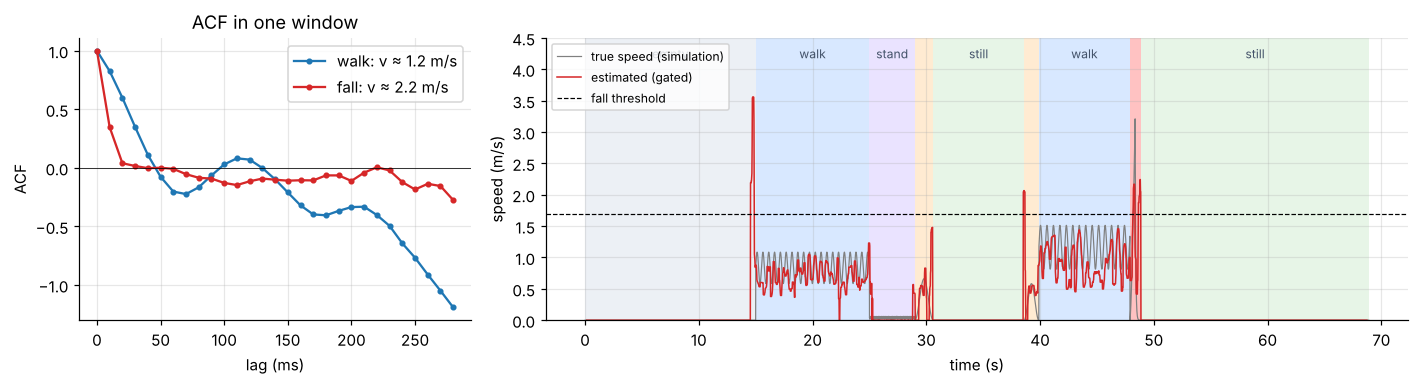

In [16]:
def acf_speed(Au, fs, win=0.3, step=0.025, vmin=0.3, vmax=6.0, smooth=9):
    P = Au ** 2; W = int(round(win * fs)); S = max(1, int(round(step * fs)))
    lag_max = min(int(np.ceil(X_VALLEY / (2 * np.pi / LAM * vmin) * fs)) + 2, W - 2)
    starts = np.arange(0, len(P) - W, S)
    seg = np.stack([P[s:s + W] for s in starts]); seg = seg - seg.mean(1, keepdims=True)
    F = np.fft.rfft(seg, n=2 * W, axis=1)
    ac = np.fft.irfft(np.abs(F) ** 2, axis=1)[:, : lag_max + 1] / (W - np.arange(lag_max + 1))[None, :, None]
    curves = (ac / (ac[:, :1] + 1e-12)).mean(2)                     # [windows, lags]
    speeds = np.zeros(len(starts))
    for n, r in enumerate(curves):
        for i in range(1, lag_max):
            if r[i] < 0 and r[i] <= r[i - 1] and r[i] <= r[i + 1]:  # first valley
                den = r[i - 1] - 2 * r[i] + r[i + 1]
                tau0 = (i + (0.5 * (r[i - 1] - r[i + 1]) / den if den else 0.0)) / fs   # parabolic refine
                vv = X_VALLEY * LAM / (2 * np.pi * tau0)
                speeds[n] = vv if vmin <= vv <= vmax else 0.0
                break
    if smooth > 1: speeds = signal.medfilt(speeds, smooth)
    return (starts + W / 2) / fs, speeds, curves

tc, sp, curves = acf_speed(Au, FS)
sp_gated = np.where(np.interp(tc, tu, me) >= TH["me_move"], sp, 0.0)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 2.2]})
lag_ms = np.arange(curves.shape[1]) / FS * 1e3
for name, col in [("walk", "C0"), ("fall", "C3")]:
    a, b, _ = [l for l in labels if l[2] == name][0]
    i = np.argmax(np.where((tc > a) & (tc < b + 0.5), sp_gated, -1))
    ax[0].plot(lag_ms, curves[i], "o-", ms=3, color=col, label=f"{name}: v ≈ {sp_gated[i]:.1f} m/s")
ax[0].axhline(0, color="k", lw=0.5); ax[0].set(xlabel="lag (ms)", ylabel="ACF", title="ACF in one window"); ax[0].legend()
ax[1].plot(truth["t"], truth["v"], color="gray", lw=0.8, label="true speed (simulation)")
ax[1].plot(tc, sp_gated, color="C3", lw=1, label="estimated (gated)")
ax[1].axhline(TH["v_fall"], ls="--", color="k", lw=0.8, label="fall threshold")
shade(ax[1], labels); ax[1].set(xlabel="time (s)", ylabel="speed (m/s)", ylim=(0, 4.5)); ax[1].legend(loc="upper left", fontsize=8)
plt.tight_layout(); save("B5_speed"); plt.show()

### B6. Tsinghua's `naive_spectrum` on ESP32 data

The same STFT view as Part A (power, so the random phase cancels). Faster motion spreads energy to higher Doppler frequency.

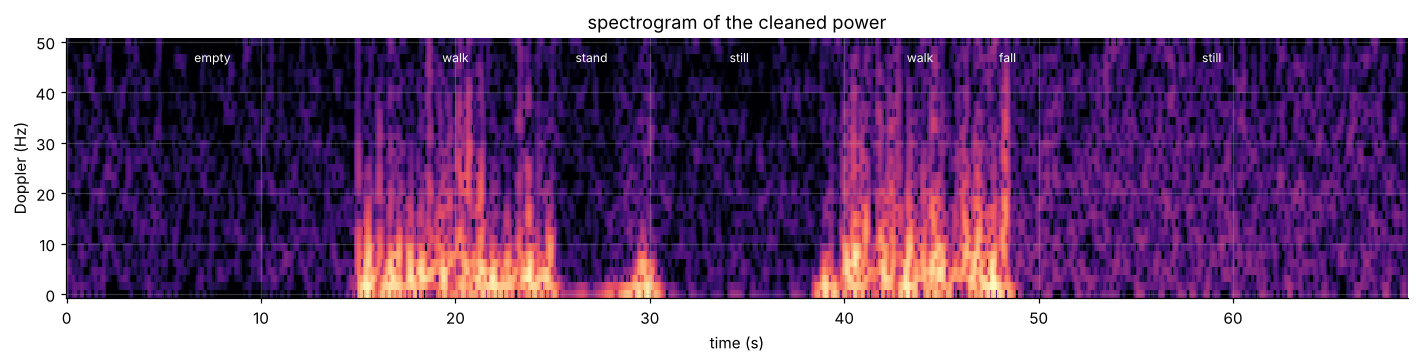

In [17]:
x = (Au ** 2).mean(1); x = x - moving(x, FS)
f_s, t_s, Z = signal.stft(x, fs=FS, window="hann", nperseg=64, noverlap=56)
fig, ax = plt.subplots(figsize=(13, 3.4))
ax.pcolormesh(t_s, f_s, 20 * np.log10(np.abs(Z) + 1e-6), shading="auto", cmap="magma", vmin=-75)
for a, b, k in labels:
    if b - a > 2.5 or k == "fall": ax.text((a + b) / 2, 46, k, color="w", ha="center", fontsize=8)
ax.set(xlabel="time (s)", ylabel="Doppler (Hz)", title="spectrogram of the cleaned power")
plt.tight_layout(); save("B6_spectrogram"); plt.show()

### B7. The fall detector — a small state machine

```
          speed ≥ v_fall  and  moving                still for 5 s  and  person present
 IDLE  ───────────────────────────────▶  CANDIDATE  ─────────────────────────────────────▶  FALL ALERT
                                              │  moves again / room looks empty
                                              └──────────────────────────────────────────▶  IDLE
```

Each condition answers one question: *was it fast?* (speed), *did they stay down?* (motion energy), *is someone still there?* (wander).

candidates (s): [14.6 14.7 14.8 14.9 38.5 38.6 38.7 48.2]
FALL ALERTS at (s): [48.19]


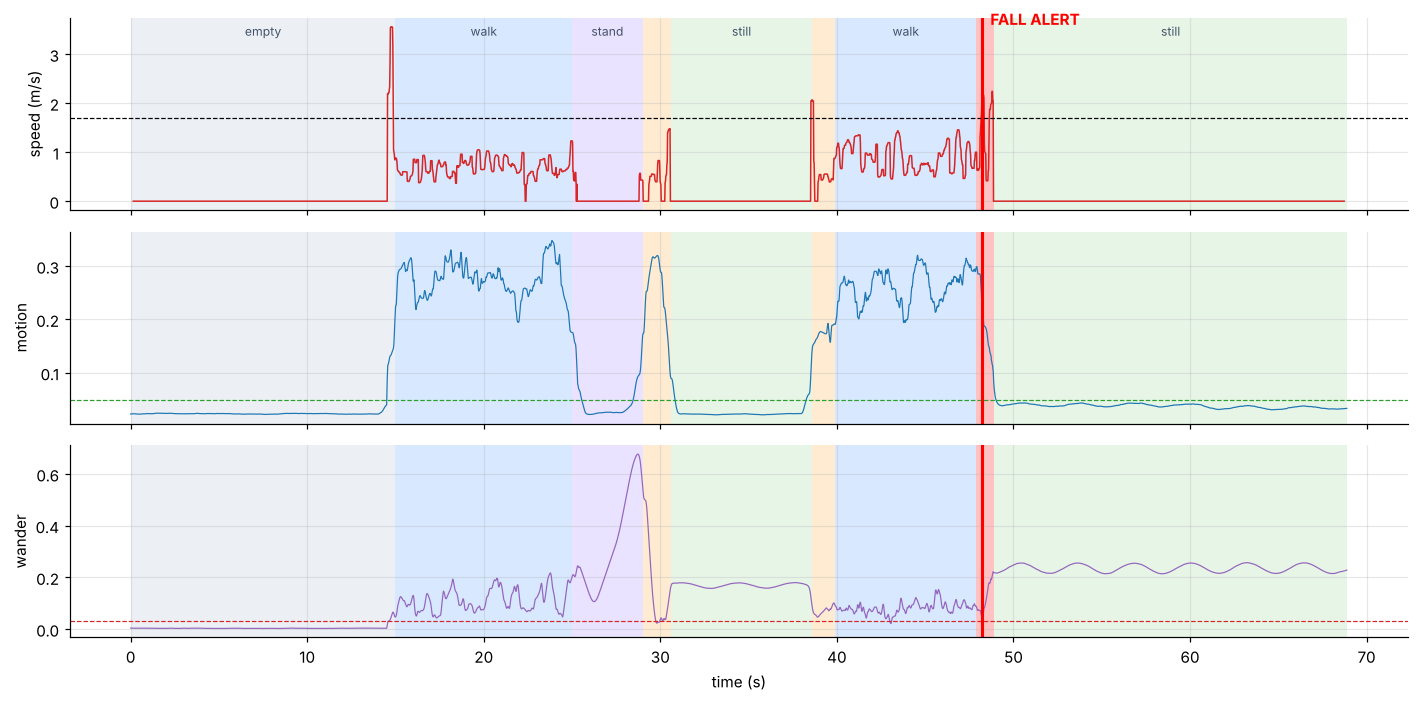

In [18]:
def detect_falls(tu, me, tc, sp, wd, th):
    alerts, cands, last = [], [], -1e9
    me_c = np.interp(tc, tu, me)
    for i in np.where((sp >= th["v_fall"]) & (me_c >= th["me_move"]))[0]:
        t0 = tc[i]
        if t0 - last < 10: continue                       # one alert per event
        cands.append(t0)
        q = (tu >= t0 + th["quiet_start"]) & (tu < t0 + th["quiet_start"] + th["quiet_len"])
        if q.sum() < 0.8 * th["quiet_len"] / np.median(np.diff(tu)): continue   # not enough data yet
        still = np.mean(me[q] < th["me_still"]) >= 0.9
        present = np.median(wd[q]) > th["wander_present"]
        if still and present:
            alerts.append(t0); last = t0
    return alerts, cands

alerts, cands = detect_falls(tu, me, tc, sp, wd, TH)
print("candidates (s):", np.round(sorted(set(np.round(cands, 1))), 1))
print("FALL ALERTS at (s):", np.round(alerts, 2))

fig, ax = plt.subplots(3, 1, figsize=(13, 6.5), sharex=True)
ax[0].plot(tc, sp_gated, color="C3", lw=1); ax[0].axhline(TH["v_fall"], ls="--", color="k", lw=0.8); ax[0].set_ylabel("speed (m/s)")
ax[1].plot(tu, me, lw=0.8); ax[1].axhline(TH["me_still"], ls="--", color="C2", lw=0.8); ax[1].set_ylabel("motion")
ax[2].plot(tu, wd, lw=0.8, color="C4"); ax[2].axhline(TH["wander_present"], ls="--", color="C3", lw=0.8); ax[2].set_ylabel("wander")
for a in ax:
    shade(a, labels, text=(a is ax[0]))
    for al in alerts: a.axvline(al, color="red", lw=2)
ax[0].text(alerts[0] + 0.5 if alerts else 0, 3.6, "FALL ALERT" if alerts else "", color="red", fontweight="bold")
ax[2].set_xlabel("time (s)"); plt.tight_layout(); save("B7_detector"); plt.show()

### B8. Does it work beyond one example? Evaluate on many sessions

We simulate sessions in **five different rooms** with five event types. Only `fall` is positive.
The hard negatives are **sitting down**, **lying down on purpose**, and a **dropped object**.
We compare our detector with a simpler **motion-only** rule (any burst of motion followed by stillness).

In [19]:
EVENTS = ["fall", "sit", "liedown", "drop", "walk"]
def make_script(event, rng):
    s = [("empty", rng.uniform(8, 10)), ("walk", rng.uniform(4, 7))]
    if event == "fall":    s += [("fall", 1.0), ("still", 12)]
    if event == "sit":     s += [("stand", 1), ("sit", rng.uniform(*DUR["sit"])), ("still", 12)]
    if event == "liedown": s += [("stand", 1), ("liedown", rng.uniform(*DUR["liedown"])), ("still", 12)]
    if event == "drop":    s += [("stand", 2), ("drop", 0.6), ("stand", 12)]
    if event == "walk":    s += [("walk", 13)]
    return s

def run_pipeline(csv_text, labels, fs=FS, th=TH, v_rule=True):
    t, H, _ = load_lab3_csv(csv_text); tu, Au = preprocess(t, H, fs)
    me = motion_energy(Au, fs)
    cal = (tu > 1) & (tu < labels[0][1] - 1)                         # the empty part of each session
    wd = wander(Au, fs, Au[cal].mean(0))
    th = dict(th, me_still=2.0 * np.percentile(me[cal], 99), me_move=4.0 * np.percentile(me[cal], 99))
    tc, sp, _ = acf_speed(Au, fs)
    if not v_rule: sp = np.full_like(sp, 99.0)                       # motion-only baseline ignores speed
    return detect_falls(tu, me, tc, sp, wd, th)[0]

N_PER_EVENT = 10          # 50 sessions take ~1 min; lower it if your laptop is slow
rng = np.random.default_rng(2026); results = []
t_start = time.time()
for i in range(N_PER_EVENT * len(EVENTS)):
    ev = EVENTS[i % len(EVENTS)]; room = int(rng.integers(0, 5))
    txt, lab, _ = simulate_session(make_script(ev, rng), fs=FS, seed=1000 + i, room_seed=room)
    results.append(dict(event=ev, room=room, ours=len(run_pipeline(txt, lab)) > 0,
                        motion_only=len(run_pipeline(txt, lab, v_rule=False)) > 0))
print(f"{len(results)} sessions in {time.time() - t_start:.0f} s\n")
print(f"{'event':10s} {'ours: alarm rate':>17s} {'motion-only: alarm rate':>24s}")
for ev in EVENTS:
    r = [x for x in results if x["event"] == ev]
    print(f"{ev:10s} {np.mean([x['ours'] for x in r]):17.0%} {np.mean([x['motion_only'] for x in r]):24.0%}")

def prf(key):
    tp = sum(x[key] and x["event"] == "fall" for x in results); fp = sum(x[key] and x["event"] != "fall" for x in results)
    fn = sum((not x[key]) and x["event"] == "fall" for x in results)
    return tp / max(tp + fp, 1), tp / max(tp + fn, 1)
for key in ["ours", "motion_only"]:
    p, r = prf(key); print(f"\n{key:12s} precision {p:.2f}  recall {r:.2f}")

50 sessions in 54 s

event       ours: alarm rate  motion-only: alarm rate
fall                     90%                     100%
sit                      30%                      90%
liedown                  30%                      90%
drop                      0%                      20%
walk                      0%                       0%

ours         precision 0.60  recall 0.90

motion_only  precision 0.33  recall 1.00


**Discuss.** Which negative causes most false alarms, and why? (Hint: compare its speed with a slow fall.) Which falls are missed — fast or slow ones?

### B9. Sampling rate: why the Lab 3 default (20 packets/s) is not enough

The first ACF valley of a 3 m/s fall is ~29 ms away. With 20 packets/s the first lag is already 50 ms.

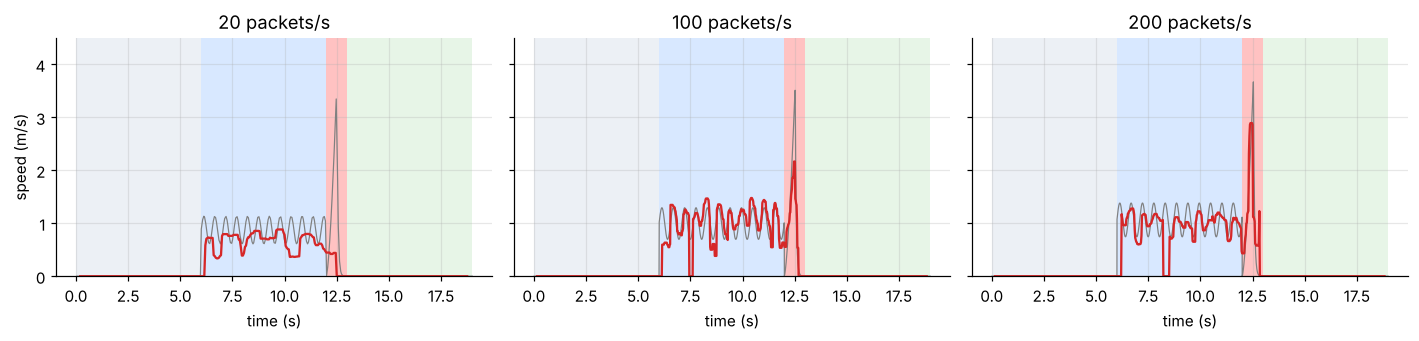

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
script = [("empty", 6), ("walk", 6), ("fall", 1.0), ("still", 6)]
for a, fs_ in zip(ax, [20, 100, 200]):
    txt, lab, tr = simulate_session(script, fs=fs_, seed=5)
    t_, H_, _ = load_lab3_csv(txt); tu_, Au_ = preprocess(t_, H_, fs_)
    me_ = motion_energy(Au_, fs_)
    tc_, sp_, _ = acf_speed(Au_, fs_, win=max(0.3, 8 / fs_))
    gate = np.interp(tc_, tu_, me_) >= 4 * np.percentile(me_[(tu_ > 1) & (tu_ < 5)], 99)
    a.plot(tr["t"], tr["v"], color="gray", lw=0.8); a.plot(tc_, np.where(gate, sp_, 0), color="C3")
    shade(a, lab, text=False); a.set(title=f"{fs_} packets/s", xlabel="time (s)", ylim=(0, 4.5))
ax[0].set_ylabel("speed (m/s)"); plt.tight_layout(); save("B9_sample_rate"); plt.show()

In Lab 3's sketch, change `PING_INTERVAL_MS` from `50` to **`10`** (100 packets/s) or **`5`** (200 packets/s).
Your router may rate-limit ping; check the real rate printed in B2.

### B10. (Optional) A learned classifier instead of hand-set thresholds

We cut a 6 s window around every motion burst, compute a few interpretable features, and train a random forest.
We test on rooms the model has **never seen** (leave-one-room-out), the honest way to report Wi-Fi sensing accuracy.

In [21]:
try:
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.metrics import confusion_matrix
except ImportError:
    RandomForestClassifier = None; print("scikit-learn not installed: pip install scikit-learn")

def event_features(csv_text, labels, fs=FS):
    t, H, _ = load_lab3_csv(csv_text); tu, Au = preprocess(t, H, fs)
    me = motion_energy(Au, fs); cal = (tu > 1) & (tu < labels[0][1] - 1)
    wd = wander(Au, fs, Au[cal].mean(0)); e = np.percentile(me[cal], 99)
    tc, sp, _ = acf_speed(Au, fs); sp = np.where(np.interp(tc, tu, me) >= 4 * e, sp, 0)
    t_ev = labels[2][0]                                 # start of the event of interest
    pre = (tu > t_ev - 3) & (tu < t_ev); post = (tu > t_ev + 2) & (tu < t_ev + 6)
    win = (tc > t_ev - 0.5) & (tc < t_ev + 3)
    return [sp[win].max(), np.percentile(sp[win], 90), me[pre].mean() / e, me[post].mean() / e,
            np.median(wd[post]), (sp[win] > 0).mean()]

if RandomForestClassifier is not None:
    rng = np.random.default_rng(7); X, y, rooms = [], [], []
    for i in range(60):
        ev = EVENTS[i % 5]; room = (i // 5) % 5          # every room sees every event
        txt, lab, _ = simulate_session(make_script(ev, rng), fs=FS, seed=5000 + i, room_seed=room)
        X.append(event_features(txt, lab)); y.append(ev); rooms.append(room)
    X, y, rooms = np.array(X), np.array(y), np.array(rooms)
    pred = np.empty_like(y)
    for r in range(5):                                  # leave-one-room-out
        clf = RandomForestClassifier(n_estimators=200, random_state=0).fit(X[rooms != r], y[rooms != r])
        pred[rooms == r] = clf.predict(X[rooms == r])
    cm = confusion_matrix(y, pred, labels=EVENTS)
    print("rows = truth, cols = prediction\n", " " * 9 + " ".join(f"{e:>8s}" for e in EVENTS))
    for e, row in zip(EVENTS, cm): print(f"{e:>8s} " + " ".join(f"{v:8d}" for v in row))
    print(f"\nleave-one-room-out accuracy: {(pred == y).mean():.2f}")
    imp = RandomForestClassifier(n_estimators=200, random_state=0).fit(X, y).feature_importances_
    print("feature importance:", dict(zip(["v_max", "v_p90", "motion_before", "motion_after", "wander_after", "moving_frac"], np.round(imp, 2))))

rows = truth, cols = prediction
              fall      sit  liedown     drop     walk
    fall       11        1        0        0        0
     sit        1        7        2        2        0
 liedown        0        2        8        1        1
    drop        1        0        1       10        0
    walk        0        0        0        0       12

leave-one-room-out accuracy: 0.80


feature importance: {'v_max': np.float64(0.12), 'v_p90': np.float64(0.12), 'motion_before': np.float64(0.1), 'motion_after': np.float64(0.28), 'wander_after': np.float64(0.1), 'moving_frac': np.float64(0.29)}


### B11. Use your own AtomS3R-M12

**Firmware (Lab 3).** In `Lab-3-CSI-serial/ino/AtomS3R_CSI_STA/AtomS3R_CSI_STA.ino` set `PING_INTERVAL_MS = 10`, upload, and use a 2.4 GHz AP you control (a phone hotspot or lab router works better than eduroam for high ping rates).

**Placement (from the hackster build).** Boards on a desk see mostly noise. Put the AP and the board about **1.2–1.5 m** high, **2–4 m** apart, with the fall area **between** them (inside the first Fresnel zone). Keep the AP channel fixed.

**Protocol.** Record one CSV per trial with Lab 3's plotter, and write down the times:

```bash
cd Lab-3-CSI-serial
python3 plot_csi.py --port /dev/cu.usbmodemXXXX --save-csv captures/trial01.csv
```

1. 15 s empty room (calibration) → 2. walk in → 3. **fall onto a mattress** (safety first; never fall on a hard floor) or sit / lie down → 4. stay still 15 s.

Then set `CSV_PATH` in B2 (and `LABELS_PATH`, or `None`) and re-run B2–B7. You will probably need to retune `TH`.

The cell below reads the board **directly** from Python instead (close other serial programs first).

In [22]:
RUN_LIVE = False                     # set True with a board attached
PORT, BAUD, SECONDS = "/dev/cu.usbmodemXXXX", 921600, 30

if RUN_LIVE:
    import serial                     # pip install pyserial
    out = DATA / "my_captures"; out.mkdir(parents=True, exist_ok=True)
    path = out / time.strftime("live_%Y%m%d_%H%M%S.csv")
    n = 0
    with serial.Serial(PORT, BAUD, timeout=1) as ser, open(path, "w") as fh:
        fh.write(HEADER + "\n"); t_end = time.time() + SECONDS
        while time.time() < t_end:
            line = ser.readline().decode("utf-8", errors="replace").strip()
            if line.startswith("CSI_DATA,"): fh.write(line + "\n"); n += 1
            elif line.startswith("#"): print(line)
    print(f"saved {n} packets to {path}  ->  set CSV_PATH = '{path}' in B2")

---
## Exercises

1. **(A3)** Run `naive_aoa` on `csi_remove_nonlinear` instead of `csi_src`. Does nonlinear calibration change the angle error? Why or why not?
2. **(A4)** Derive the minimum packet rate needed to measure 3 m/s with the first-valley method if you need the valley at ≥ 2 samples.
3. **(B3)** Remove the AGC normalization and re-run B4–B7. What breaks, and where?
4. **(B5)** Replace the first valley (x₀ = 4.49) with the first **peak** (x₀ = 7.73). Which one is more robust at 100 packets/s? Explain with the plot in A4.
5. **(B8)** Find the threshold `v_fall` that maximizes F1. Then change the room seeds (`room_seed`) and test again. What does this tell you about tuning on one room?
6. **(B11)** Record 5 falls (on a mattress) and 5 sit-downs with your board. Report precision and recall, and one figure of a missed or false event with your explanation.

## Credits
* Part A: Python port of the MATLAB code from the Tsinghua MobiSense group's *Hands-on Wireless Sensing with Wi-Fi* (Ch. 3–4) and the *Understanding CSI* chapter. Test data © the original authors.
* Part B format and capture: Lab 3 (`AtomS3R_CSI_STA.ino`, `plot_csi.py`), built on Espressif ESP-CSI. Simulated data are for teaching; they are **not** hardware measurements.